<div style="box-sizing: border-box; width: 100%; max-width: 100%; background: linear-gradient(135deg, #0f172a 0%, #1e293b 60%, #0f172a 100%); padding: 28px 32px; border-radius: 16px; border: 1.5px solid rgba(56, 189, 248, 0.35); border-left: 6px solid #38bdf8; box-shadow: 0 10px 25px -5px rgba(0, 0, 0, 0.4), 0 8px 10px -6px rgba(0, 0, 0, 0.3); font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; margin: 10px 0 24px 0; overflow: hidden; color: #f8fafc;">
  
  <!-- Topic Badges -->
  <div style="display: flex; align-items: center; gap: 5px; margin-bottom: 14px; flex-wrap: wrap;">
    <span style="background: rgba(74, 222, 128, 0.15); color: #4ade80; font-size: 0.75rem; font-weight: 600; padding: 4px 12px; border-radius: 9999px; border: 1px solid rgba(74, 222, 128, 0.35); text-transform: uppercase; letter-spacing: 0.05em;">Autumn 2026</span>
    <span style="background: rgba(251, 191, 36, 0.15); color: #fbbf24; font-size: 0.75rem; font-weight: 600; padding: 4px 12px; border-radius: 9999px; border: 1px solid rgba(251, 191, 36, 0.35); text-transform: uppercase; letter-spacing: 0.05em;">IIT KGP</span>
  </div>

  <!-- Course Title -->
  <h1 style="color: #ffffff; font-size: 1.95rem; font-weight: 700; margin: 0 0 6px 0; border: none; padding: 0; letter-spacing: -0.02em; line-height: 1.2;">
    AI60209 &bull; <a href="https://ranjan-sarkar.github.io/#robot" target="_blank" style="color: #ffffff; text-decoration: none; border-bottom: 1.5px dashed rgba(56, 189, 248, 0.5);">AI for Robot Autonomy</a>
  </h1>

  <!-- Tutorial Subtitle -->
  <h2 style="color: #93c5fd; font-size: 1.9rem; font-weight: 600; margin: 0 0 14px 0; border: none; padding: 0; letter-spacing: -0.01em;">
    Tutorial 5: REINFORCE + Optuna
  </h2>

  <!-- Description -->
  <p style="color: #94a3b8; font-size: 0.95rem; line-height: 1.6; margin: 0 0 16px 0;">
    
  </p>

  <!-- Instructor / TA Info Row -->
  <div style="display: flex; gap: 16px; margin-bottom: 16px; flex-wrap: wrap; font-size: 1rem; color: #cbd5e1; gap: 4px">
    <div>
      <span style="color: #94a3b8; font-weight: 600;">Instructor:</span>
      <a href="https://prabhatkmishra.github.io/people.html" target="_blank" style="color: #f1f5f9; font-weight: 600; text-decoration: none; margin-left: 4px;">Dr. Prabhat Kumar Mishra</a>
    </div>
    <div>
      <span style="color: #94a3b8; font-weight: 600;">TAs:</span>
      <span style="color: #f1f5f9; font-weight: 600; margin-left: 4px;">Samarth Gupta</span>
    </div>
  </div>

  <!-- Reference & Quick Links Footer -->
  <div style="padding-top: 14px; border-top: 1px solid rgba(255, 255, 255, 0.1); display: flex; align-items: center; gap: 10px; flex-wrap: wrap;">
    <span style="color: #64748b; font-size: 0.8rem; font-weight: 700; text-transform: uppercase; letter-spacing: 0.05em;">References:</span>
    <a href="https://github.com/huggingface/deep-rl-class/blob/main/notebooks/unit4/unit4.ipynb" target="_blank" style="color: #c084fc; font-size: 0.85rem; font-weight: 600; text-decoration: none; background: rgba(168, 85, 247, 0.1); padding: 5px 12px; border-radius: 6px; border: 1px solid rgba(168, 85, 247, 0.25); display: inline-flex; align-items: center; gap: 4px;">
      🤗 Hugging Face Deep RL Class — Unit 4 ↗
    </a>
    <a href="https://github.com/araffin/tools-for-robotic-rl-icra2022/blob/main/notebooks/optuna_lab.ipynb" target="_blank" style="color: #38bdf8; font-size: 0.85rem; font-weight: 600; text-decoration: none; background: rgba(56, 189, 248, 0.1); padding: 5px 12px; border-radius: 6px; border: 1px solid rgba(56, 189, 248, 0.25); display: inline-flex; align-items: center; gap: 4px;">
      💻 Tools for Robotic RL — Optuna lab ↗
    </a>
  </div>

</div>

## 1. The task: balance the pole

At each step, the agent sees the cart's state and chooses **left** or **right**. It receives a reward of `+1` for every step the pole stays balanced.

The goal is to maximize the total reward in an episode.

**State** → policy → **action** → environment → **reward + next state**

In [1]:
# Install the small set of libraries used in this notebook
%pip -q install "gymnasium[classic-control]" optuna pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import random
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import optuna

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

set_seed(7)
device = torch.device("cpu") 
print("PyTorch:", torch.__version__)
print("Gymnasium:", gym.__version__)

PyTorch: 2.13.0+cpu
Gymnasium: 1.2.3


C:\Users\91844\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Peek at the environment

CartPole observations are four numbers: cart position, cart velocity, pole angle, and pole angular velocity. The two actions are left and right.

In [3]:
env = gym.make("CartPole-v1")
state, info = env.reset(seed=7)

print("Observation:", state)
print("Observation shape:", env.observation_space.shape)
print("Available actions:", env.action_space.n)

env.close()

Observation: [ 0.01250955  0.03972138  0.02756857 -0.02747928]
Observation shape: (4,)
Available actions: 2


## 2. A random agent

Before learning, choose actions at random. The plot shows how many steps it survives in each episode.

**Question:** Does random behavior consistently keep the pole balanced?

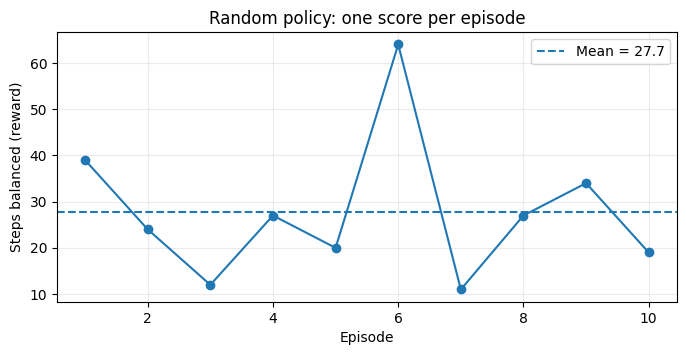

In [4]:
env = gym.make("CartPole-v1")
random_rewards = []

for episode in range(10):
    state, info = env.reset(seed=episode)
    total_reward = 0
    done = False

    while not done:
        action = env.action_space.sample()
        state, reward, terminated, truncated, info = env.step(action)
        total_reward += reward
        done = terminated or truncated

    random_rewards.append(total_reward)

env.close()

plt.figure(figsize=(8, 3.5))
plt.plot(range(1, len(random_rewards) + 1), random_rewards, marker="o")
plt.axhline(np.mean(random_rewards), linestyle="--",
            label=f"Mean = {np.mean(random_rewards):.1f}")
plt.xlabel("Episode")
plt.ylabel("Steps balanced (reward)")
plt.title("Random policy: one score per episode")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 3. REINFORCE 

REINFORCE is a **policy-gradient** algorithm. A neural network outputs action probabilities, and the agent samples an action from them.

### Return from time step $t$

$$
G_t = r_t + \gamma r_{t+1} + \gamma^2 r_{t+2} + \cdots
$$

Here, $\gamma$ controls how much future rewards matter.

### Policy-gradient update

$$
L(\theta) = -\sum_t \log \pi_\theta(a_t \mid s_t)\,G_t
$$

Gradient descent on this loss tends to increase the probability of actions that led to high returns. The minus sign turns reward maximization into loss minimization.

### REINFORCE: the episode loop

1. Run one full episode and save each action's log-probability and reward.
2. Calculate discounted returns $G_t$, working backward from the end.
3. Compute the loss above and update the policy network.
4. Repeat for many episodes.


## 4. Policy network

The network maps the four state values to two action scores. `softmax` turns the scores into probabilities.

We sample an action and record its log-probability for the REINFORCE loss.

In [ ]:
class PolicyNetwork(nn.Module):
    def __init__(self, state_size=4, hidden_size=32, action_size=2):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(state_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, action_size)
        )

    def forward(self, state):
        action_scores = self.layers(state)
        return torch.softmax(action_scores, dim=-1)


policy = PolicyNetwork()
example_state = torch.tensor([0.0, 0.1, 0.02, -0.03], dtype=torch.float32)
print("Action probabilities:", policy(example_state).detach().numpy())

Action probabilities: [0.54808086 0.45191917]


## 5. Implement REINFORCE


In [ ]:
def train_reinforce(
    episodes=120,
    learning_rate=0.01,
    gamma=0.99,
    hidden_size=32,
    seed=7,
    show_progress=False
):
    set_seed(seed)
    env = gym.make("CartPole-v1")
    policy = PolicyNetwork(hidden_size=hidden_size).to(device)
    optimizer = optim.Adam(policy.parameters(), lr=learning_rate)
    episode_rewards = []

    for episode in range(episodes):
        state, info = env.reset(seed=seed + episode)
        log_probs = []
        rewards = []
        done = False

        # 1) Collect one episode
        while not done:
            state_tensor = torch.tensor(state, dtype=torch.float32)
            probabilities = policy(state_tensor)
            distribution = Categorical(probabilities)
            action = distribution.sample()

            next_state, reward, terminated, truncated, info = env.step(action.item())

            log_probs.append(distribution.log_prob(action))
            rewards.append(reward)
            state = next_state
            done = terminated or truncated

        # 2) Calculate discounted returns G_t, from the end backwards
        returns = []
        G = 0
        for reward in reversed(rewards):
            G = reward + gamma * G
            returns.insert(0, G)

        returns = torch.tensor(returns, dtype=torch.float32)

        # Normalize returns for more stable updates
        if len(returns) > 1 and returns.std(unbiased=False) > 1e-8:
            returns = (returns - returns.mean()) / (returns.std(unbiased=False) + 1e-8)

        # 3) REINFORCE loss: -sum(log pi(a|s) * G_t)
        loss = sum(
            -log_prob * G_t
            for log_prob, G_t in zip(log_probs, returns)
        )

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        episode_rewards.append(sum(rewards))

        if show_progress and (episode + 1) % 25 == 0:
            print(f"Episode {episode + 1:3d} | reward = {episode_rewards[-1]:.0f}")

    env.close()
    return policy, episode_rewards

In [7]:
def evaluate_policy(policy, episodes=5, seed=500):
    """Evaluate with greedy actions; no learning or parameter updates."""
    env = gym.make("CartPole-v1")
    scores = []

    for episode in range(episodes):
        state, info = env.reset(seed=seed + episode)
        total_reward = 0
        done = False

        while not done:
            state_tensor = torch.tensor(state, dtype=torch.float32)
            with torch.no_grad():
                probabilities = policy(state_tensor)
            action = int(torch.argmax(probabilities).item())

            state, reward, terminated, truncated, info = env.step(action)
            total_reward += reward
            done = terminated or truncated

        scores.append(total_reward)

    env.close()
    return scores

### Train a baseline

Start with a fixed learning rate, discount factor, and hidden-layer size. The smoothed curve helps reveal the trend; individual episodes can vary a lot.

Episode  25 | reward = 28


Episode  50 | reward = 68


Episode  75 | reward = 50


Episode 100 | reward = 105


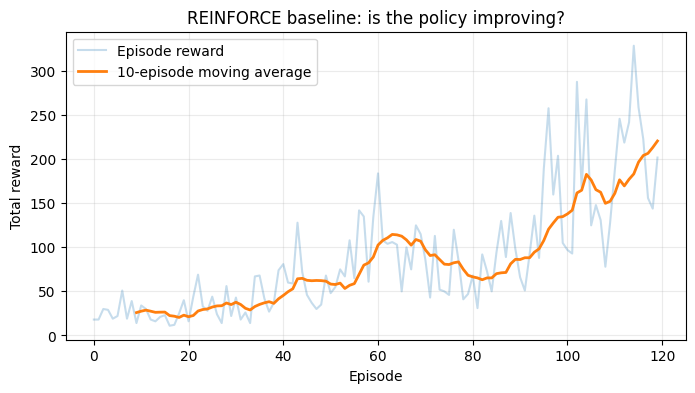

Mean reward over last 10 episodes: 220.8


In [8]:
baseline_settings = {
    "learning_rate": 0.01,
    "gamma": 0.99,
    "hidden_size": 32
}

baseline_policy, baseline_rewards = train_reinforce(
    episodes=120, seed=10, show_progress=True, **baseline_settings
)

def moving_average(values, window=10):
    values = np.asarray(values, dtype=float)
    if len(values) < window:
        return values
    return np.convolve(values, np.ones(window) / window, mode="valid")

plt.figure(figsize=(8, 4))
plt.plot(baseline_rewards, alpha=0.25, label="Episode reward")
plt.plot(np.arange(9, len(baseline_rewards)), moving_average(baseline_rewards, 10),
         linewidth=2, label="10-episode moving average")
plt.xlabel("Episode")
plt.ylabel("Total reward")
plt.title("REINFORCE baseline: is the policy improving?")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("Mean reward over last 10 episodes:", round(np.mean(baseline_rewards[-10:]), 1))

## 6. Why use Optuna?

The learning rate and discount factor can strongly affect learning. Trying combinations manually is tedious.

Optuna runs **trials**. Each trial:
1. proposes hyperparameters,
2. trains REINFORCE briefly **with three different random seeds**,
3. evaluates each trained policy,
4. returns the average evaluation score for Optuna to maximize.

We will search only three understandable settings:

| Hyperparameter | Search range | Meaning |
|---|---|---|
| Learning rate | 0.003–0.02 (log scale) | Size of each network update |
| Discount γ | 0.95–0.999 | Weight given to future rewards |
| Hidden units | 16, 32, or 64 | Size of the policy network |

**Why several seeds?** REINFORCE is very sensitive to randomness: the *same* hyperparameters can score 20 with one seed and 500 with another. If every trial used a single seed, Optuna would mostly find the configuration that got lucky on that seed, and the result would not transfer. Averaging over a few seeds makes each trial's score a fairer estimate of how good the configuration really is.

Each trial still uses a small training budget and five greedy evaluation episodes, so scores remain noisy. The best trial is a candidate, not proof of a universal optimum.

### Pseudocode for the tuning loop

```text
for each Optuna trial:
    choose learning_rate, gamma, hidden_size
    for each of 3 tuning seeds:
        train REINFORCE 
        evaluate the greedy policy on 5 fixed episodes
    score = mean evaluation reward across the seeds
    tell Optuna the score

return the trial with the highest score
```

In [9]:
TUNING_SEEDS = [100, 200, 300]  # several seeds so one lucky run cannot dominate


def objective(trial):
    learning_rate = trial.suggest_float(
        "learning_rate", 0.003, 0.02, log=True
    )
    gamma = trial.suggest_float("gamma", 0.95, 0.999)
    hidden_size = trial.suggest_categorical(
        "hidden_size", [16, 32, 64]
    )

    seed_scores = []
    for seed in TUNING_SEEDS:
        # Train REINFORCE with the sampled hyperparameters
        policy, rewards = train_reinforce(
            episodes=100,
            learning_rate=learning_rate,
            gamma=gamma,
            hidden_size=hidden_size,
            seed=seed
        )

        # Evaluate on the same fixed episodes for every trial
        scores = evaluate_policy(policy, episodes=5, seed=900)
        seed_scores.append(np.mean(scores))

    return float(np.mean(seed_scores))


study = optuna.create_study(
    direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=7)
)
study.optimize(objective, n_trials=10, show_progress_bar=True)

print("Best evaluation score:", round(study.best_value, 2))
print("Best settings:", study.best_params)

[I 2026-10-28 00:28:45,459] A new study created in memory with name: no-name-992731d9-c710-429c-b997-192f16ef8ca2



  0%|          | 0/10 [00:00<?, ?it/s]


  0%|          | 0/10 [00:09<?, ?it/s]


Best trial: 0. Best value: 169.333:   0%|          | 0/10 [00:09<?, ?it/s]


Best trial: 0. Best value: 169.333:  10%|█         | 1/10 [00:09<01:22,  9.19s/it]

[I 2026-10-28 00:28:54,655] Trial 0 finished with value: 169.33333333333334 and parameters: {'learning_rate': 0.003467307199339976, 'gamma': 0.9882160208197656, 'hidden_size': 64}. Best is trial 0 with value: 169.33333333333334.


... (33 outputs left out)


Best trial: 2. Best value: 422.2:  90%|█████████ | 9/10 [02:09<00:13, 13.17s/it]


Best trial: 2. Best value: 422.2: 100%|██████████| 10/10 [02:09<00:00, 13.96s/it]


Best trial: 2. Best value: 422.2: 100%|██████████| 10/10 [02:09<00:00, 12.97s/it]

[I 2026-10-28 00:30:55,160] Trial 9 finished with value: 321.06666666666666 and parameters: {'learning_rate': 0.011742989885847334, 'gamma': 0.9702365996265778, 'hidden_size': 16}. Best is trial 2 with value: 422.2.
Best evaluation score: 422.2
Best settings: {'learning_rate': 0.010882903685105472, 'gamma': 0.9893832127691143, 'hidden_size': 16}


### Visualize the search

Each point is one configuration tried by Optuna. The highest point is the best observed trial in this small search.

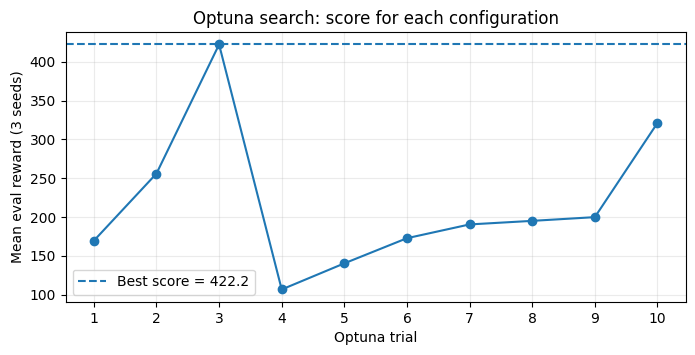

Best configuration found:
  learning_rate: 0.010882903685105472
  gamma: 0.9893832127691143
  hidden_size: 16


In [10]:
trial_numbers = [trial.number + 1 for trial in study.trials]
trial_scores = [trial.value for trial in study.trials]

plt.figure(figsize=(8, 3.5))
plt.plot(trial_numbers, trial_scores, marker="o", linewidth=1.5)
plt.axhline(study.best_value, linestyle="--",
            label=f"Best score = {study.best_value:.1f}")
plt.xticks(trial_numbers)
plt.xlabel("Optuna trial")
plt.ylabel("Mean eval reward (3 seeds)")
plt.title("Optuna search: score for each configuration")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

print("Best configuration found:")
for name, value in study.best_params.items():
    print(f"  {name}: {value}")

## 7. Retrain and compare fairly

A tuning trial is only a short experiment. To compare fairly, we train **both** configurations on the same set of **fresh seeds** (not used during tuning), with the same number of episodes, and evaluate every policy on the **same evaluation episodes**.

Comparing a single baseline run against a single tuned run is misleading: with REINFORCE, the seed can matter more than the hyperparameters. So we report the mean and standard deviation **across seeds**, and show every seed's score as a dot.

For evaluation only, we choose the most probable action (`argmax`) to make the result less noisy. Training still samples actions as REINFORCE requires.

A tuned agent can still score worse: ten trials and a short training budget are not enough to guarantee that Optuna finds a better configuration.

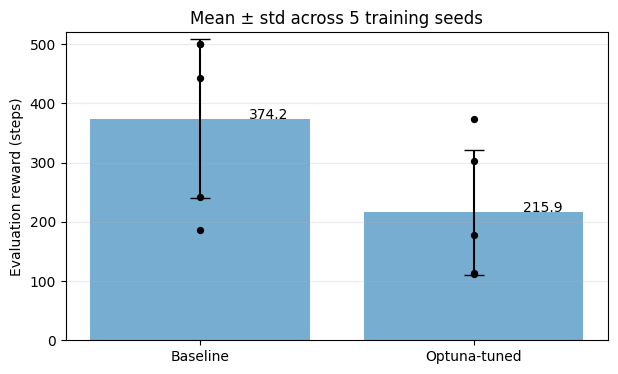

Baseline score per seed: [500.0, 242.0, 186.0, 500.0, 443.2]
Tuned score per seed:    [373.6, 303.2, 111.4, 177.4, 113.8]
Baseline mean ± std: 374.2 ± 133.6
Tuned mean ± std:    215.9 ± 105.2


In [11]:
COMPARE_SEEDS = [1, 2, 3, 4, 5]  # fresh seeds, not used during tuning


def train_and_evaluate(settings, seeds, episodes=120):
    # Train one policy per seed and return the policies and their mean eval scores
    policies, seed_scores = [], []
    for seed in seeds:
        policy, rewards = train_reinforce(episodes=episodes, seed=seed, **settings)
        policies.append(policy)
        seed_scores.append(float(np.mean(evaluate_policy(policy, episodes=5, seed=500))))
    return policies, seed_scores


baseline_policies, baseline_seed_scores = train_and_evaluate(baseline_settings, COMPARE_SEEDS)
tuned_policies, tuned_seed_scores = train_and_evaluate(study.best_params, COMPARE_SEEDS)
tuned_policy = tuned_policies[0]  # used by the animation cell below

labels = ["Baseline", "Optuna-tuned"]
all_scores = [baseline_seed_scores, tuned_seed_scores]
means = [np.mean(s) for s in all_scores]
stds = [np.std(s) for s in all_scores]

plt.figure(figsize=(7, 4))
bars = plt.bar(labels, means, yerr=stds, capsize=7, alpha=0.6)
for x, scores in enumerate(all_scores):
    plt.scatter([x] * len(scores), scores, color="black", zorder=3, s=18)
plt.ylabel("Evaluation reward (steps)")
plt.title(f"Mean ± std across {len(COMPARE_SEEDS)} training seeds")
plt.ylim(0, 520)
plt.grid(axis="y", alpha=0.25)

for bar, mean in zip(bars, means):
    plt.text(bar.get_x() + bar.get_width() / 2 + 0.25, mean,
             f"{mean:.1f}", ha="center")

plt.show()

print("Baseline score per seed:", [round(s, 1) for s in baseline_seed_scores])
print("Tuned score per seed:   ", [round(s, 1) for s in tuned_seed_scores])
print(f"Baseline mean ± std: {means[0]:.1f} ± {stds[0]:.1f}")
print(f"Tuned mean ± std:    {means[1]:.1f} ± {stds[1]:.1f}")

### Why can the tuned agent lose to the baseline?

**What happened in our run**

| | Score during tuning (seeds 100, 200, 300) | Score on fresh seeds (1–5) |
|---|---|---|
| Baseline | 332 | **374** |
| Optuna's best | **422** | 216 |

Optuna's pick really did beat the baseline, but only on the seeds it was tuned on. On new seeds, the ranking flipped.

**Why this happens**

- **REINFORCE is very noisy.** The *same* settings can score 100 with one seed and 500 with another. Three seeds is too few to tell a good config from a lucky one.
- **Optuna barely got to learn.** Its default sampler uses the first 10 trials for random exploration. With `n_trials=10`, this whole search was random guessing.

**How to avoid it**

1. **Use more seeds per trial** (e.g. 5 or more) so each score is closer to the config's real quality.
2. **Run more trials** (e.g. 25 or more), or lower `n_startup_trials`, so Optuna's smart search actually kicks in.
3. **Add the baseline as a trial** with `study.enqueue_trial(baseline_settings)`, so it competes directly.
4. **Always test on fresh seeds** that were not used during tuning, as we did above.


>  **Takeaway:** a tuned result is only as trustworthy as the evaluation behind it. With noisy RL, reliable tuning needs more compute than this small experiment.

## 8. Watch the pole balance (one short episode)

This cell records **one episode only** and displays it as a small animation. It does not train the model, so the extra computation is minimal. The episode is capped at 250 steps to keep the animation short.

Run this after training. If rendering fails in a local setup, skip this optional cell; the rest of the notebook works without it.

Rendered episode reward: 250.0 steps


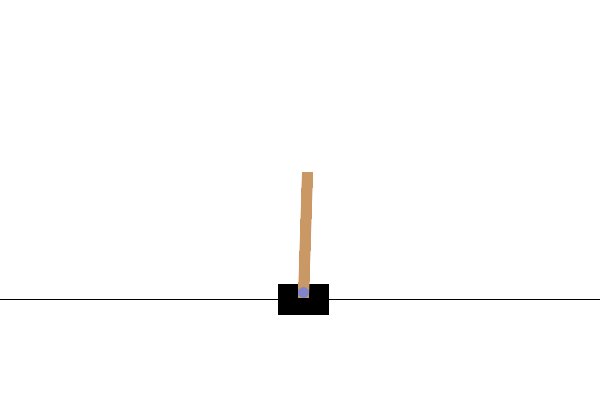

In [12]:
# Record one short rollout from the Optuna-tuned policy
from io import BytesIO
from PIL import Image as PILImage
from IPython.display import display, Image as IPyImage

render_env = gym.make("CartPole-v1", render_mode="rgb_array")
state, info = render_env.reset(seed=42)
frames = []
total_reward = 0

for step in range(250):
    # Keep only every second frame to make the GIF smaller
    if step % 2 == 0:
        frames.append(PILImage.fromarray(render_env.render()))

    state_tensor = torch.tensor(state, dtype=torch.float32)
    with torch.no_grad():
        probabilities = tuned_policy(state_tensor)
    action = int(torch.argmax(probabilities).item())

    state, reward, terminated, truncated, info = render_env.step(action)
    total_reward += reward

    if terminated or truncated:
        frames.append(PILImage.fromarray(render_env.render()))
        break

render_env.close()

gif_buffer = BytesIO()
frames[0].save(
    gif_buffer,
    format="GIF",
    save_all=True,
    append_images=frames[1:],
    duration=50,
    loop=0
)

print(f"Rendered episode reward: {total_reward} steps")
display(IPyImage(data=gif_buffer.getvalue()))
